In [14]:
# Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

In [16]:
# 1. Load data
df = pd.read_csv("dataset/marketing_AB.csv")
print(df.shape)
df.head()

(588101, 7)


,Unnamed: 0,user id,test group,converted,total ads,most ads day,most ads hour
0,0,1069124,ad,False,130,Monday,20
1,1,1119715,ad,False,93,Tuesday,22
2,2,1144181,ad,False,21,Tuesday,18
3,3,1435133,ad,False,355,Tuesday,10
4,4,1015700,ad,False,276,Friday,14


In [17]:
# 2. First look: structure, types, missing values
df.info()
print("\nMissing values:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate user ids:", df["user id"].duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 588101 entries, 0 to 588100
Data columns (total 7 columns):
 #   Column         Non-Null Count   Dtype 
---  ------         --------------   ----- 
 0   Unnamed: 0     588101 non-null  int64 
 1   user id        588101 non-null  int64 
 2   test group     588101 non-null  object
 3   converted      588101 non-null  bool  
 4   total ads      588101 non-null  int64 
 5   most ads day   588101 non-null  object
 6   most ads hour  588101 non-null  int64 
dtypes: bool(1), int64(4), object(2)
memory usage: 27.5+ MB

Missing values:
 Unnamed: 0       0
user id          0
test group       0
converted        0
total ads        0
most ads day     0
most ads hour    0
dtype: int64

Duplicate rows: 0
Duplicate user ids: 0


In [18]:
# 3. Cleaning
# Drop the leftover index column from the CSV export
if "Unnamed: 0" in df.columns:
    df = df.drop(columns=["Unnamed: 0"])

In [19]:
# Standardise column names (snake_case)
df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_")

In [20]:
# Make sure converted is boolean and create a 0/1 version for averaging
df["converted"] = df["converted"].astype(bool)
df["converted_int"] = df["converted"].astype(int)

In [21]:
# Order weekdays properly for charts
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
df["most_ads_day"] = pd.Categorical(df["most_ads_day"], categories=day_order, ordered=True)

In [22]:
df.describe(include="all")

,user_id,test_group,converted,total_ads,most_ads_day,most_ads_hour,converted_int
count,5.881010e+05,588101,588101,588101.000000,588101,588101.000000,588101.000000
unique,NaN,2,2,NaN,7,NaN,NaN
top,NaN,ad,False,NaN,Friday,NaN,NaN
freq,NaN,564577,573258,NaN,92608,NaN,NaN
mean,1.310692e+06,NaN,NaN,24.820876,NaN,14.469061,0.025239
std,2.022260e+05,NaN,NaN,43.715181,NaN,4.834634,0.156850
min,9.000000e+05,NaN,NaN,1.000000,NaN,0.000000,0.000000
25%,1.143190e+06,NaN,NaN,4.000000,NaN,11.000000,0.000000
50%,1.313725e+06,NaN,NaN,13.000000,NaN,14.000000,0.000000
75%,1.484088e+06,NaN,NaN,27.000000,NaN,18.000000,0.000000


In [23]:
# 4. Sanity checks (write these findings in your README)
print("Test groups:\n", df["test_group"].value_counts())
print("\nGroup share (%):\n", (df["test_group"].value_counts(normalize=True) * 100).round(2))
print("\nHour range:", df["most_ads_hour"].min(), "-", df["most_ads_hour"].max())
print("Total ads range:", df["total_ads"].min(), "-", df["total_ads"].max())

Test groups:
 test_group
ad     564577
psa     23524
Name: count, dtype: int64

Group share (%):
 test_group
ad     96.0
psa     4.0
Name: proportion, dtype: float64

Hour range: 0 - 23
Total ads range: 1 - 2065


In [24]:
# Outliers in total_ads
print("\ntotal_ads percentiles:\n", df["total_ads"].quantile([.5, .75, .9, .95, .99, 1]))


total_ads percentiles:
 0.50      13.0
0.75      27.0
0.90      57.0
0.95      88.0
0.99     202.0
1.00    2065.0
Name: total_ads, dtype: float64


In [25]:
# 5. Overall conversion rate by group
conv = (
    df.groupby("test_group")["converted_int"]
    .agg(users="count", conversions="sum", conversion_rate="mean")
    .reset_index()
)
conv["conversion_rate_%"] = (conv["conversion_rate"] * 100).round(3)
print(conv)

  test_group   users  conversions  conversion_rate  conversion_rate_%
0         ad  564577        14423         0.025547              2.555
1        psa   23524          420         0.017854              1.785


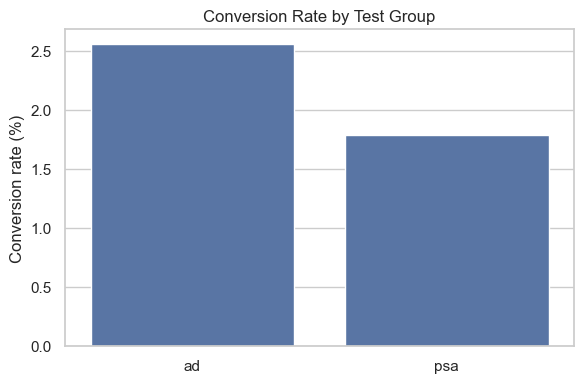

In [26]:
plt.figure(figsize=(6, 4))
sns.barplot(data=conv, x="test_group", y="conversion_rate_%")
plt.title("Conversion Rate by Test Group")
plt.ylabel("Conversion rate (%)")
plt.xlabel("")
plt.tight_layout()
plt.savefig("outputs/conversion_by_group.png", dpi=150)
plt.show()

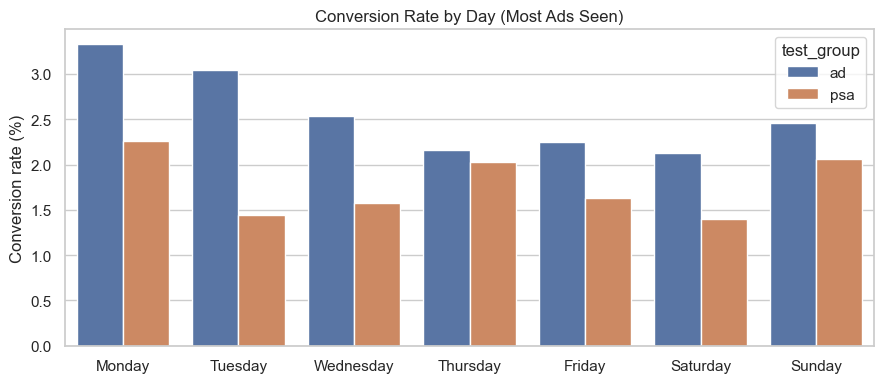

In [27]:
# 6. Conversion by day of week
by_day = (
    df.groupby(["most_ads_day", "test_group"], observed=True)["converted_int"]
    .mean().mul(100).reset_index(name="conversion_rate_%")
)
plt.figure(figsize=(9, 4))
sns.barplot(data=by_day, x="most_ads_day", y="conversion_rate_%", hue="test_group")
plt.title("Conversion Rate by Day (Most Ads Seen)")
plt.xlabel("")
plt.ylabel("Conversion rate (%)")
plt.tight_layout()
plt.savefig("outputs/conversion_by_day.png", dpi=150)
plt.show()

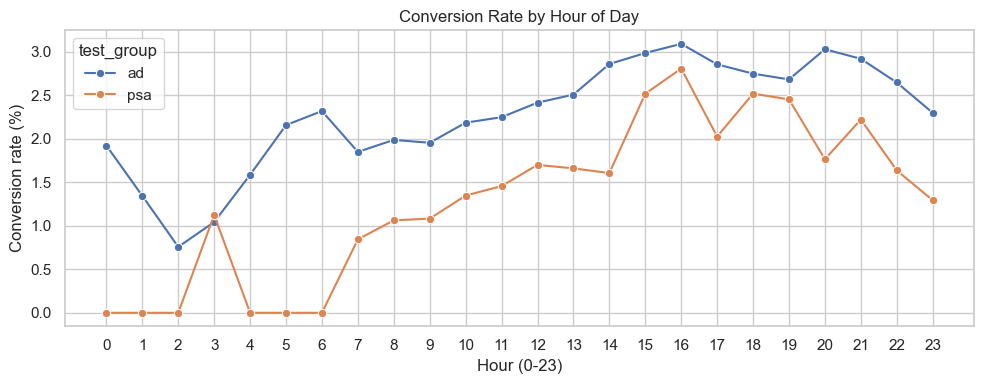

In [28]:
# 7. Conversion by hour of day
by_hour = (
    df.groupby(["most_ads_hour", "test_group"])["converted_int"]
    .mean().mul(100).reset_index(name="conversion_rate_%")
)
plt.figure(figsize=(10, 4))
sns.lineplot(data=by_hour, x="most_ads_hour", y="conversion_rate_%", hue="test_group", marker="o")
plt.title("Conversion Rate by Hour of Day")
plt.xlabel("Hour (0-23)")
plt.ylabel("Conversion rate (%)")
plt.xticks(range(0, 24))
plt.tight_layout()
plt.savefig("outputs/conversion_by_hour.png", dpi=150)
plt.show()

  ads_bucket test_group   users  conversion_rate  conversion_rate_%
0       1-10         ad  249499         0.003259               0.33
1       1-10        psa   11276         0.003991               0.40
2      11-25         ad  163135         0.010169               1.02
3      11-25        psa    6112         0.009980               1.00
4      26-50         ad   85740         0.035421               3.54
5      26-50        psa    3273         0.026581               2.66
6     51-100         ad   44149         0.116311              11.63
7     51-100        psa    1853         0.057744               5.77
8       100+         ad   22054         0.171352              17.14
9       100+        psa    1010         0.118812              11.88


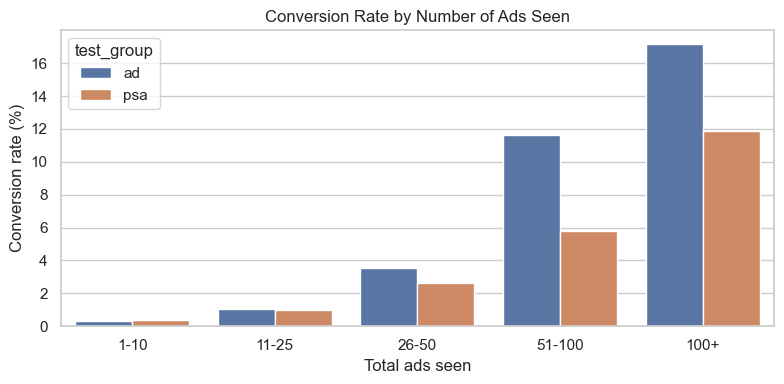

In [29]:
# 8. Conversion vs. ad exposure (bucketed)
bins = [0, 10, 25, 50, 100, df["total_ads"].max()]
labels = ["1-10", "11-25", "26-50", "51-100", "100+"]
df["ads_bucket"] = pd.cut(df["total_ads"], bins=bins, labels=labels, include_lowest=True)
 
by_bucket = (
    df.groupby(["ads_bucket", "test_group"], observed=True)["converted_int"]
    .agg(users="count", conversion_rate="mean").reset_index()
)
by_bucket["conversion_rate_%"] = (by_bucket["conversion_rate"] * 100).round(2)
print(by_bucket)
 
plt.figure(figsize=(8, 4))
sns.barplot(data=by_bucket, x="ads_bucket", y="conversion_rate_%", hue="test_group")
plt.title("Conversion Rate by Number of Ads Seen")
plt.xlabel("Total ads seen")
plt.ylabel("Conversion rate (%)")
plt.tight_layout()
plt.savefig("outputs/conversion_by_ad_exposure.png", dpi=150)
plt.show()

In [31]:
# 9. Save the cleaned dataset
df.to_csv("dataset/marketing_AB_clean.csv", index=False)
print("Saved cleaned data:", df.shape)

Saved cleaned data: (588101, 8)
